## 1. Import and Config

In [ ]:
import json
import random          # [VĐ3] cần cho việc cố định seed
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from tqdm import tqdm
import ssl
ssl._create_default_https_context = ssl._create_unverified_context  # [Lần 5] cho phép tải trọng số pretrained qua SSL trên Windows

# [VĐ3] Cố định seed — phải chạy TRƯỚC mọi thao tác ngẫu nhiên
# (khởi tạo model ở cell 7, shuffle/augment ở cell 5). Mục đích: mỗi run
# xuất phát giống nhau → so sánh run-to-run mới tách được "cải thiện thật".
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

IMG_SIZE = 352
BATCH_SIZE = 8
LEARNING_RATE = 0.0001
EPOCHS = 60
PATIENCE = 10           # Dừng sớm nếu val không cải thiện

DEVICE = "cuda"
DATA = Path("..") / "data"
SPLIT_PATH = DATA / "splits" / "unet_split.json"
SAVE_DIR = Path("..") / "checkpoints"
SAVE_DIR.mkdir(parents=True, exist_ok=True)
BEST_MODEL_PATH = SAVE_DIR / "unet_best.pth"

## 2. Dataset

In [ ]:
class PolypDataset(Dataset):
    """Dataset cho bài toán polyp segmentation.
    Đọc ảnh + mask từ unet_split.json, resize và augmentation.
    """

    def __init__(self, entries, data_dir, img_size=256, augment=False):
        """
        Args:
            entries: danh sách dict từ unet_split.json (mỗi dict có image, mask, label)
            data_dir: thư mục gốc chứa data
            img_size: kích thước resize (vuông)
            augment: có áp dụng augmentation không (chỉ dùng cho train)
        """
        self.entries = entries
        self.data_dir = Path(data_dir)
        self.img_size = img_size
        self.augment = augment

    def __len__(self):
        return len(self.entries)

    def __getitem__(self, idx):
        entry = self.entries[idx]

        # Đọc ảnh và mask
        image = Image.open(self.data_dir / entry["image"]).convert("RGB")
        mask = Image.open(self.data_dir / entry["mask"]).convert("L")  # Grayscale

        # Resize về cùng kích thước
        image = image.resize((self.img_size, self.img_size), Image.BILINEAR)
        mask = mask.resize((self.img_size, self.img_size), Image.NEAREST)

        # Chuyển sang numpy
        image = np.array(image, dtype=np.float32) / 255.0  # Chuẩn hóa [0, 1]
        mask = np.array(mask, dtype=np.float32) / 255.0
        mask = (mask > 0.5).astype(np.float32)  # Nhị phân hóa mask

        # Augmentation (chỉ áp dụng cho tập train)
        if self.augment:
            # Lật ngang ngẫu nhiên
            if np.random.rand() > 0.5:
                image = np.flip(image, axis=1).copy()
                mask = np.flip(mask, axis=1).copy()
            # Lật dọc ngẫu nhiên
            if np.random.rand() > 0.5:
                image = np.flip(image, axis=0).copy()
                mask = np.flip(mask, axis=0).copy()
            # Xoay 90/180/270 độ ngẫu nhiên
            k = np.random.randint(0, 4)
            image = np.rot90(image, k, axes=(0, 1)).copy()
            mask = np.rot90(mask, k, axes=(0, 1)).copy()
            # Điều chỉnh độ sáng ngẫu nhiên (chỉ ảnh, không áp dụng cho mask)
            brightness = np.random.uniform(0.8, 1.2)
            image = np.clip(image * brightness, 0, 1).astype(np.float32)


        # Chuyển sang tensor: (H, W, C) → (C, H, W)
        image = torch.from_numpy(image).permute(2, 0, 1)
        mask = torch.from_numpy(mask).unsqueeze(0)  # (1, H, W)

        return image, mask

## 3. DataLoader

In [3]:
# Đọc file split
with open(SPLIT_PATH, "r") as f:
    splits = json.load(f)

print(f"Train: {len(splits['train'])} | Val: {len(splits['val'])} | Test: {len(splits['test'])}")

# Tạo dataset
train_dataset = PolypDataset(splits["train"], DATA, IMG_SIZE, augment=True)
val_dataset = PolypDataset(splits["val"], DATA, IMG_SIZE, augment=False)
test_dataset = PolypDataset(splits["test"], DATA, IMG_SIZE, augment=False)

# [VĐ3] Cố định thứ tự shuffle của train_loader, độc lập với RNG toàn cục
g = torch.Generator()
g.manual_seed(SEED)

# [VĐ1] num_workers=0: Windows + Jupyter spawn worker bị treo (đã kiểm chứng).
# Augmentation chạy trên process chính (đã seed ở cell 1) → vẫn tái lập được.
# pin_memory giữ lại để đi kèm non_blocking=True bên training loop (lợi ích biên).
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=0, pin_memory=True, generator=g,
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=0, pin_memory=True,
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=0, pin_memory=True,
)

# Kiểm tra nhanh 1 batch
images, masks = next(iter(train_loader))
print(f"Batch ảnh : {images.shape}")   # (B, 3, 256, 256)
print(f"Batch mask: {masks.shape}")    # (B, 1, 256, 256)
print(f"Giá trị mask: min={masks.min()}, max={masks.max()}")

Train: 1520 | Val: 190 | Test: 190
Batch ảnh : torch.Size([8, 3, 352, 352])
Batch mask: torch.Size([8, 1, 352, 352])
Giá trị mask: min=0.0, max=1.0


## 4. Kiến trúc U-Net

In [4]:
class DoubleConv(nn.Module):
    """Khối 2 lần Conv → BatchNorm → ReLU (dùng chung cho encoder và decoder)."""

    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class UNet(nn.Module):
    """Kiến trúc U-Net cơ bản.
    Encoder: 4 tầng giảm kích thước (64 → 128 → 256 → 512)
    Bottleneck: 1024 channels
    Decoder: 4 tầng tăng kích thước + skip connections
    Output: 1 channel (xác suất polyp tại mỗi pixel)
    """

    def __init__(self, in_channels=3, out_channels=1):
        super().__init__()

        # === ENCODER (nửa trái — trích xuất features) ===
        self.enc1 = DoubleConv(in_channels, 64)
        self.enc2 = DoubleConv(64, 128)
        self.enc3 = DoubleConv(128, 256)
        self.enc4 = DoubleConv(256, 512)
        self.pool = nn.MaxPool2d(2)

        # === BOTTLENECK (đáy chữ U) ===
        self.bottleneck = DoubleConv(512, 1024)

        # === DECODER (nửa phải — khôi phục kích thước) ===
        self.up4 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride=2)
        self.dec4 = DoubleConv(1024, 512)   # 1024 vì concat với skip connection

        self.up3 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.dec3 = DoubleConv(512, 256)

        self.up2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.dec2 = DoubleConv(256, 128)

        self.up1 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec1 = DoubleConv(128, 64)

        # === OUTPUT ===
        self.out_conv = nn.Conv2d(64, out_channels, kernel_size=1)

    def forward(self, x):
        # Encoder
        e1 = self.enc1(x)                 # (B, 64, 256, 256)
        e2 = self.enc2(self.pool(e1))     # (B, 128, 128, 128)
        e3 = self.enc3(self.pool(e2))     # (B, 256, 64, 64)
        e4 = self.enc4(self.pool(e3))     # (B, 512, 32, 32)

        # Bottleneck
        b = self.bottleneck(self.pool(e4))  # (B, 1024, 16, 16)

        # Decoder + skip connections
        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))   # (B, 512, 32, 32)
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))  # (B, 256, 64, 64)
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))  # (B, 128, 128, 128)
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))  # (B, 64, 256, 256)

        return self.out_conv(d1)  # (B, 1, 256, 256) — logits, chưa qua sigmoid


# Khởi tạo model
model = UNet().to(DEVICE)

# Đếm số lượng parameters
total_params = sum(p.numel() for p in model.parameters())
print(f"Tổng parameters: {total_params:,}")
print(f"Kích thước model: ~{total_params * 4 / 1024**2:.1f} MB")

Tổng parameters: 31,037,633
Kích thước model: ~118.4 MB


## 5. Loss and metrics

In [5]:
def dice_coefficient(pred, target, threshold=0.5, smooth=1e-6):
    """Tính Dice coefficient. Dice(∅, ∅) = 1.0 (quy ước y tế)."""
    pred_bin = (torch.sigmoid(pred) > threshold).float()
    dice_scores = []
    for i in range(pred_bin.shape[0]):
        p = pred_bin[i].view(-1)
        t = target[i].view(-1)
        if p.sum() == 0 and t.sum() == 0:
            dice_scores.append(1.0)
            continue
        intersection = (p * t).sum()
        dice = (2.0 * intersection + smooth) / (p.sum() + t.sum() + smooth)
        dice_scores.append(dice.item())
    return np.mean(dice_scores)


def iou_score(pred, target, threshold=0.5, smooth=1e-6):
    """Tính IoU. IoU(∅, ∅) = 1.0 (cùng quy ước với Dice)."""
    pred_bin = (torch.sigmoid(pred) > threshold).float()
    iou_scores = []
    for i in range(pred_bin.shape[0]):
        p = pred_bin[i].view(-1)
        t = target[i].view(-1)
        if p.sum() == 0 and t.sum() == 0:
            iou_scores.append(1.0)
            continue
        intersection = (p * t).sum()
        union = p.sum() + t.sum() - intersection
        iou = (intersection + smooth) / (union + smooth)
        iou_scores.append(iou.item())
    return np.mean(iou_scores)


class BCEDiceLoss(nn.Module):
    """BCE + Dice Loss. [VĐ4] Dice tính TỪNG ẢNH rồi trung bình (macro),
    khớp với metric dice_coefficient — thay vì gộp cả batch như trước.
    Lý do: bản gộp batch để ảnh polyp lớn chi phối gradient, polyp nhỏ bị
    pha loãng; bản per-image phạt đều mọi ảnh → ép model quan tâm cả polyp nhỏ.
    """
    def __init__(self):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()

    def forward(self, pred, target):
        bce_loss = self.bce(pred, target)

        pred_sig = torch.sigmoid(pred)
        smooth = 1e-6
        B = pred.shape[0]
        p = pred_sig.view(B, -1)          # [VĐ4] tách theo từng ảnh
        t = target.view(B, -1)
        inter = (p * t).sum(dim=1)
        dice = (2.0 * inter + smooth) / (p.sum(dim=1) + t.sum(dim=1) + smooth)
        dice_loss = 1 - dice.mean()       # trung bình trên batch

        return bce_loss + dice_loss


criterion = BCEDiceLoss()
# [VĐ2] AdamW + weight_decay: regularization rẻ, siết overfitting nhẹ
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
# Bỏ verbose=True (đã deprecated); ta tự in LR trong cell 11 để thấy khi nào scheduler giảm
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='max', patience=5, factor=0.5
)

## 6. Training Loop

In [6]:
def train_one_epoch(model, loader, criterion, optimizer, scaler, device):
    """Chạy 1 epoch training. [VĐ1] Dùng AMP (mixed precision)."""
    model.train()
    total_loss = 0
    total_dice = 0

    for images, masks in loader:
        images, masks = images.to(device, non_blocking=True), masks.to(device, non_blocking=True)

        optimizer.zero_grad()
        with torch.amp.autocast("cuda"):          # [VĐ1] tính fp16: nhanh hơn + nhẹ VRAM
            outputs = model(images)
            loss = criterion(outputs, masks)
        scaler.scale(loss).backward()             # scale loss tránh underflow gradient fp16
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item()
        total_dice += dice_coefficient(outputs, masks)

    return total_loss / len(loader), total_dice / len(loader)


@torch.no_grad()
def validate(model, loader, criterion, device):
    """Đánh giá trên tập validation. [VĐ1] Cũng bọc autocast cho nhẹ VRAM."""
    model.eval()
    total_loss = 0
    total_dice = 0

    for images, masks in loader:
        images, masks = images.to(device, non_blocking=True), masks.to(device, non_blocking=True)
        with torch.amp.autocast("cuda"):
            outputs = model(images)
            loss = criterion(outputs, masks)
        total_loss += loss.item()
        total_dice += dice_coefficient(outputs, masks)

    return total_loss / len(loader), total_dice / len(loader)


# === BẮT ĐẦU TRAINING ===
scaler = torch.amp.GradScaler("cuda")   # [VĐ1] quản lý scale gradient cho AMP — tạo 1 lần

history = {
    "train_loss": [], "val_loss": [],
    "train_dice": [], "val_dice": []
}

best_val_dice = 0.0
patience_counter = 0

print(f"{'Epoch':>5} | {'Train Loss':>10} | {'Val Loss':>10} | {'Train Dice':>10} | {'Val Dice':>10} | {'LR':>8} | {'Status'}")
print("-" * 90)

for epoch in range(1, EPOCHS + 1):
    train_loss, train_dice = train_one_epoch(model, train_loader, criterion, optimizer, scaler, DEVICE)
    val_loss, val_dice = validate(model, val_loader, criterion, DEVICE)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_dice"].append(train_dice)
    history["val_dice"].append(val_dice)

    scheduler.step(val_dice)
    current_lr = optimizer.param_groups[0]['lr']   # [VĐ3] để thấy scheduler giảm LR lúc nào

    status = ""
    if val_dice > best_val_dice:
        best_val_dice = val_dice
        patience_counter = 0
        torch.save(model.state_dict(), BEST_MODEL_PATH)
        status = "✓ Saved"
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"\nDừng sớm tại epoch {epoch} — Val Dice không cải thiện sau {PATIENCE} epoch.")
            break

    print(f"{epoch:>5} | {train_loss:>10.4f} | {val_loss:>10.4f} | {train_dice:>10.4f} | {val_dice:>10.4f} | {current_lr:>8.1e} | {status}")

print(f"\nBest Val Dice: {best_val_dice:.4f}")
print(f"Model đã lưu tại: {BEST_MODEL_PATH}")

Epoch | Train Loss |   Val Loss | Train Dice |   Val Dice |       LR | Status
------------------------------------------------------------------------------------------
    1 |     1.2938 |     1.1979 |     0.2960 |     0.4862 |  1.0e-04 | ✓ Saved
    2 |     1.1554 |     1.0737 |     0.4444 |     0.5672 |  1.0e-04 | ✓ Saved
    3 |     1.0796 |     1.0442 |     0.5094 |     0.6377 |  1.0e-04 | ✓ Saved
    4 |     1.0336 |     0.9686 |     0.5707 |     0.6421 |  1.0e-04 | ✓ Saved
    5 |     0.9949 |     0.9345 |     0.5880 |     0.7018 |  1.0e-04 | ✓ Saved
    6 |     0.9542 |     0.9050 |     0.6159 |     0.6015 |  1.0e-04 | 
    7 |     0.9247 |     0.8881 |     0.6225 |     0.7395 |  1.0e-04 | ✓ Saved
    8 |     0.9019 |     0.8838 |     0.6338 |     0.6618 |  1.0e-04 | 
    9 |     0.8660 |     0.8412 |     0.6544 |     0.7732 |  1.0e-04 | ✓ Saved
   10 |     0.8476 |     0.8348 |     0.6595 |     0.7669 |  1.0e-04 | 
   11 |     0.8184 |     0.7970 |     0.6698 |     0.8024 |  1

## 7. Visualize train and valid

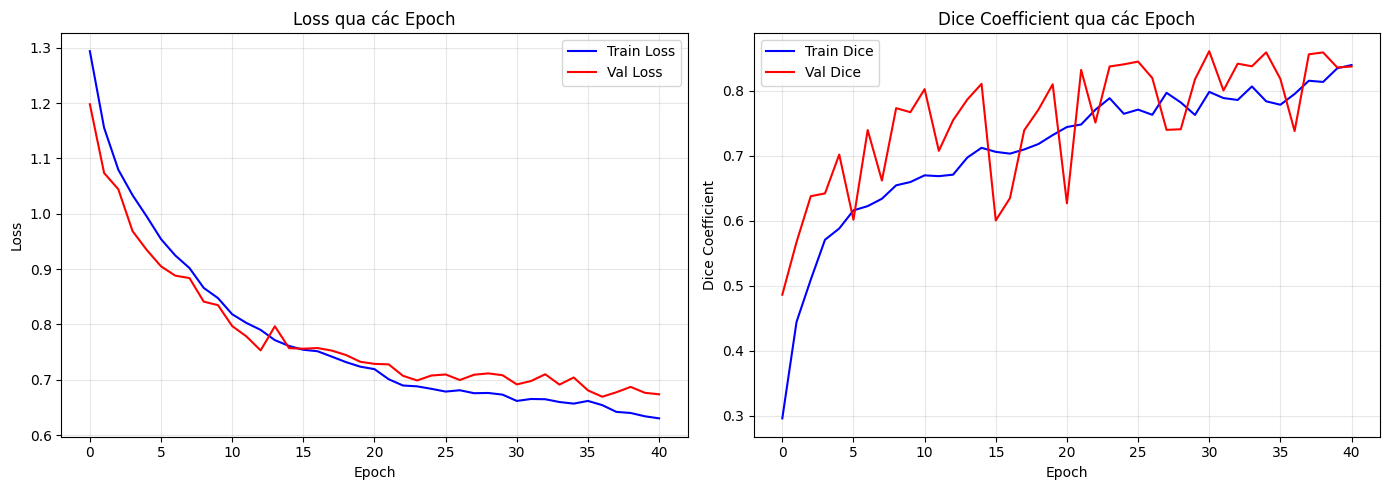

Đã lưu biểu đồ tại: ..\checkpoints\training_curves.png


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Biểu đồ Loss ---
axes[0].plot(history["train_loss"], label="Train Loss", color="blue")
axes[0].plot(history["val_loss"], label="Val Loss", color="red")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_title("Loss qua các Epoch")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# --- Biểu đồ Dice ---
axes[1].plot(history["train_dice"], label="Train Dice", color="blue")
axes[1].plot(history["val_dice"], label="Val Dice", color="red")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Dice Coefficient")
axes[1].set_title("Dice Coefficient qua các Epoch")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(SAVE_DIR / "training_curves.png", dpi=150)
plt.show()

print("Đã lưu biểu đồ tại:", SAVE_DIR / "training_curves.png")

## 8. Đánh giá tập test

In [ ]:
# Load model tốt nhất
model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=DEVICE))
model.eval()

all_dice, all_iou = [], []
polyp_dice, polyp_iou = [], []
normal_dice, normal_iou = [], []          # [thêm] chỉ ảnh normal

test_labels = [e["label"] for e in splits["test"]]
sample_idx = 0

with torch.no_grad():
    for images, masks in test_loader:
        images, masks = images.to(DEVICE), masks.to(DEVICE)
        outputs = model(images)

        for i in range(images.shape[0]):
            pred_single = outputs[i:i+1]
            mask_single = masks[i:i+1]

            d = dice_coefficient(pred_single, mask_single)
            iou = iou_score(pred_single, mask_single)

            all_dice.append(d)
            all_iou.append(iou)

            if sample_idx < len(test_labels):
                if test_labels[sample_idx] == "polyp":
                    polyp_dice.append(d)
                    polyp_iou.append(iou)
                elif test_labels[sample_idx] == "normal":     # [thêm]
                    normal_dice.append(d)
                    normal_iou.append(iou)

            sample_idx += 1

# === KẾT QUẢ ===
print("=" * 50)
print("KẾT QUẢ TRÊN TẬP TEST")
print("=" * 50)
print(f"\n--- Toàn bộ test set ({len(all_dice)} ảnh) ---")
print(f"  Dice : {np.mean(all_dice):.4f} ± {np.std(all_dice):.4f}")
print(f"  IoU  : {np.mean(all_iou):.4f} ± {np.std(all_iou):.4f}")

print(f"\n--- Chỉ ảnh polyp ({len(polyp_dice)} ảnh) ---")
print(f"  Dice : {np.mean(polyp_dice):.4f} ± {np.std(polyp_dice):.4f}")
print(f"  IoU  : {np.mean(polyp_iou):.4f} ± {np.std(polyp_iou):.4f}")

# [thêm] Ảnh normal — đo specificity (khả năng KHÔNG báo polyp giả)
print(f"\n--- Chỉ ảnh normal ({len(normal_dice)} ảnh) ---")
print(f"  Dice : {np.mean(normal_dice):.4f} ± {np.std(normal_dice):.4f}")
print(f"  IoU  : {np.mean(normal_iou):.4f} ± {np.std(normal_iou):.4f}")
# Diễn giải rõ hơn: với ảnh normal, Dice mỗi ảnh chỉ là 1.0 (sạch) hoặc ~0 (có FP)
clean = sum(1 for d in normal_dice if d > 0.5)
print(f"  Ảnh sạch (không false positive): {clean}/{len(normal_dice)} = {clean/len(normal_dice)*100:.1f}%")

C:\Users\USER\AppData\Local\Temp\ipykernel_2640\3262021217.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location

KẾT QUẢ TRÊN TẬP TEST

--- Toàn bộ test set (190 ảnh) ---
  Dice : 0.8445 ± 0.2713
  IoU  : 0.7982 ± 0.2918

--- Chỉ ảnh polyp (100 ảnh) ---
  Dice : 0.8246 ± 0.1870
  IoU  : 0.7366 ± 0.2232

--- Chỉ ảnh normal (90 ảnh) ---
  Dice : 0.8667 ± 0.3399
  Ảnh sạch (không false positive): 78/90 = 86.7%


## 9. Visualize predict

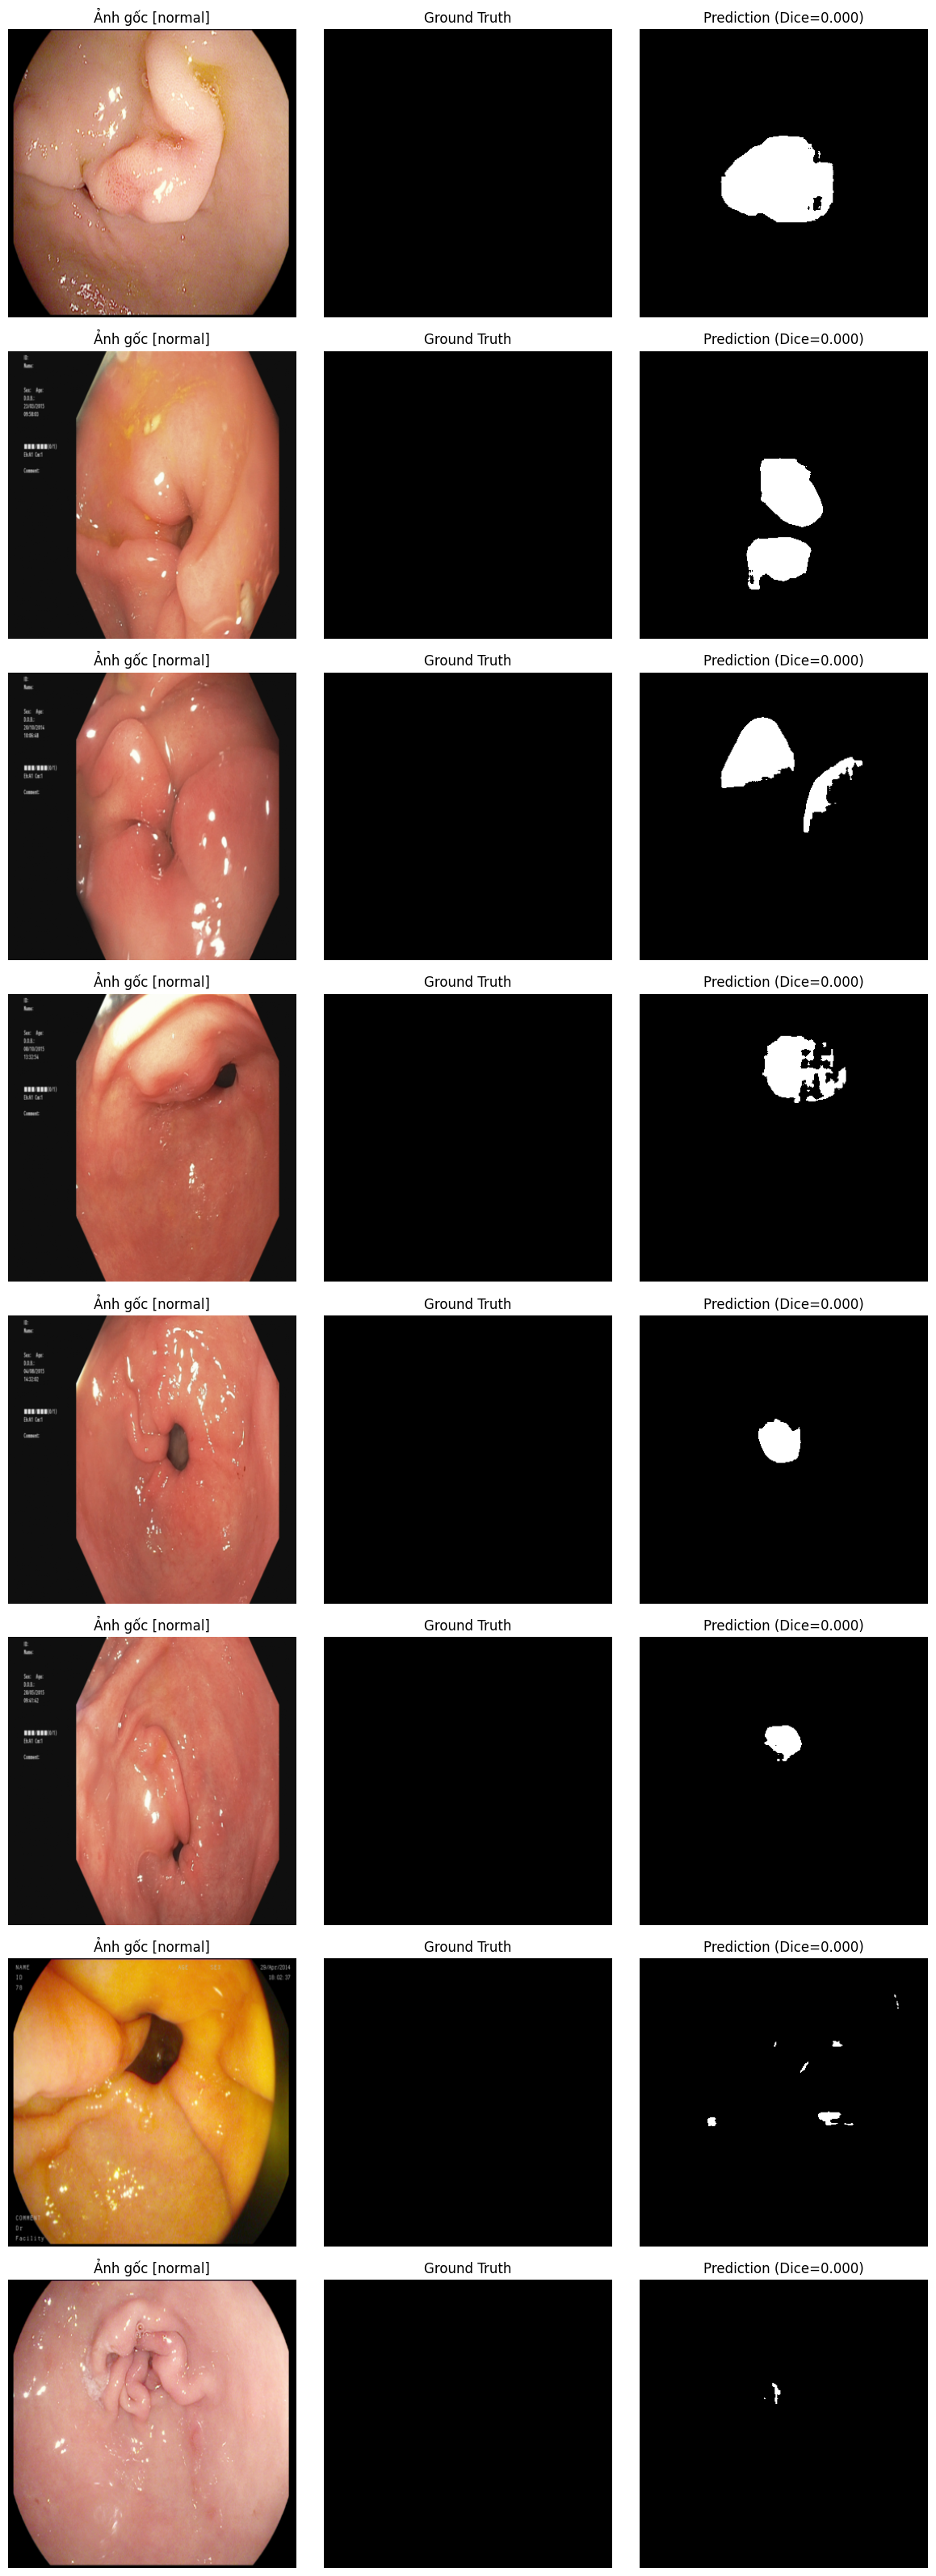

Đã lưu kết quả tại: ..\checkpoints\test_worst_predictions.png


In [9]:
@torch.no_grad()
def visualize_predictions(model, dataset, splits_entries, dice_scores, device, num_samples=8):
    """[VĐ5] Hiển thị num_samples ảnh có Dice THẤP NHẤT (failure cases).
    dice_scores: list all_dice từ cell 15, cùng thứ tự với splits["test"]
    (đúng thứ tự vì test_loader để shuffle=False).
    Lộ luôn cả 2 kiểu lỗi: bỏ sót polyp (miss) và vẽ polyp giả trên ảnh normal.
    """
    model.eval()

    # [VĐ5] chọn num_samples ảnh Dice thấp nhất thay vì random
    indices = np.argsort(dice_scores)[:num_samples]

    fig, axes = plt.subplots(len(indices), 3, figsize=(12, 4 * len(indices)))

    for row, idx in enumerate(indices):
        image, mask = dataset[idx]
        label = splits_entries[idx]["label"]

        pred = model(image.unsqueeze(0).to(device))
        pred_mask = (torch.sigmoid(pred) > 0.5).float().cpu().squeeze()

        img_np = image.permute(1, 2, 0).numpy()
        mask_np = mask.squeeze().numpy()
        pred_np = pred_mask.numpy()

        d = dice_coefficient(pred, mask.unsqueeze(0).to(device))

        axes[row, 0].imshow(img_np)
        axes[row, 0].set_title(f"Ảnh gốc [{label}]")
        axes[row, 0].axis("off")

        axes[row, 1].imshow(mask_np, cmap="gray")
        axes[row, 1].set_title("Ground Truth")
        axes[row, 1].axis("off")

        axes[row, 2].imshow(pred_np, cmap="gray")
        axes[row, 2].set_title(f"Prediction (Dice={d:.3f})")
        axes[row, 2].axis("off")

    plt.tight_layout()
    plt.savefig(SAVE_DIR / "test_worst_predictions.png", dpi=150)
    plt.show()

# [VĐ5] truyền all_dice (từ cell 15) vào để chọn ca tệ nhất
visualize_predictions(model, test_dataset, splits["test"], all_dice, DEVICE, num_samples=8)
print("Đã lưu kết quả tại:", SAVE_DIR / "test_worst_predictions.png")